In [1]:
import pandas as pd
import os

BASE_DIR = os.getcwd()
df = pd.read_csv(os.path.join(BASE_DIR, 'Telco-Customer-Churn.csv'))

print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df['Churn'].value_counts())

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [2]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['TotalCharges'])

In [3]:
churn_rate = df['Churn'].value_counts(normalize=True) * 100
print(churn_rate)

df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64

In [4]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 72],
                             labels=['0-1yr', '1-2yr', '2-4yr', '4-6yr'])
df.groupby('TenureGroup')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

TenureGroup
0-1yr    47.678161
1-2yr    28.710938
2-4yr    20.388959
4-6yr     9.513176
Name: Churn, dtype: float64

In [5]:
df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

InternetService
DSL            18.998344
Fiber optic    41.892765
No              7.434211
Name: Churn, dtype: float64

In [6]:
df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

PaymentMethod
Bank transfer (automatic)    16.731518
Credit card (automatic)      15.253123
Electronic check             45.285412
Mailed check                 19.201995
Name: Churn, dtype: float64

In [7]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [8]:
for col in ['OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection']:
    print(f"{col}\n")
    print(df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100))
    print()

OnlineSecurity

OnlineSecurity
No                     41.778667
No internet service     7.434211
Yes                    14.640199
Name: Churn, dtype: float64

TechSupport

TechSupport
No                     41.647465
No internet service     7.434211
Yes                    15.196078
Name: Churn, dtype: float64

OnlineBackup

OnlineBackup
No                     39.941691
No internet service     7.434211
Yes                    21.567010
Name: Churn, dtype: float64

DeviceProtection

DeviceProtection
No                     39.140271
No internet service     7.434211
Yes                    22.539289
Name: Churn, dtype: float64



In [9]:
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)
print(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].corr())

                  tenure  MonthlyCharges  TotalCharges  ChurnFlag
tenure          1.000000        0.246862      0.825880  -0.354049
MonthlyCharges  0.246862        1.000000      0.651065   0.192858
TotalCharges    0.825880        0.651065      1.000000  -0.199484
ChurnFlag      -0.354049        0.192858     -0.199484   1.000000


In [10]:
# Visualization / Charts
import matplotlib.pyplot as plt
import os

BASE_DIR = r'C:\Users\LEGION\Documents\portfolio-projects\02-churn-analysis'

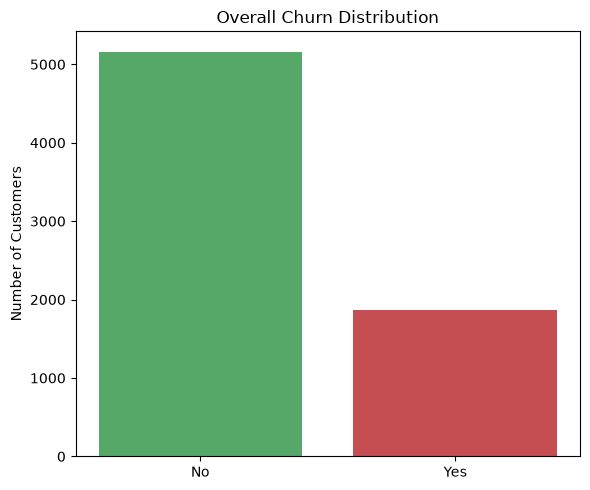

In [11]:
#1. Overall churn rate → simple pie or bar (bar is cleaner for 2 categories)
churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(6, 5))
plt.bar(churn_counts.index, churn_counts.values, color=['#55A868', '#C44E52'])
plt.ylabel('Number of Customers')
plt.title('Overall Churn Distribution')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'churn_overall.png'), dpi=150)
plt.show()

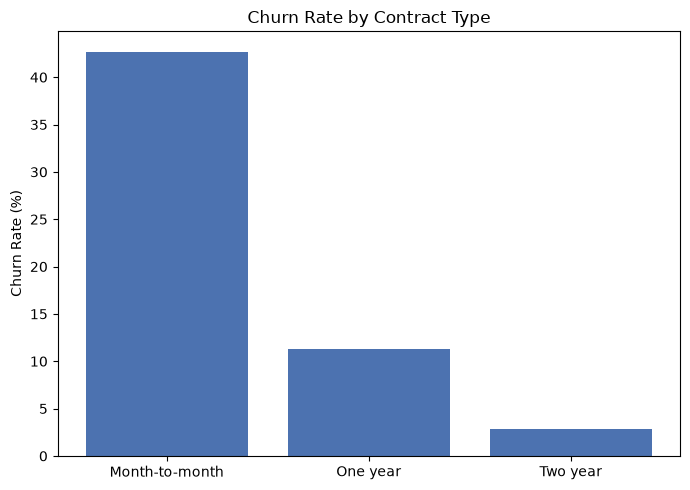

In [12]:
# 2. Churn rate by contract type
contract_churn = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(7, 5))
plt.bar(contract_churn.index, contract_churn.values, color='#4C72B0')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Contract Type')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'churn_by_contract.png'), dpi=150)
plt.show()

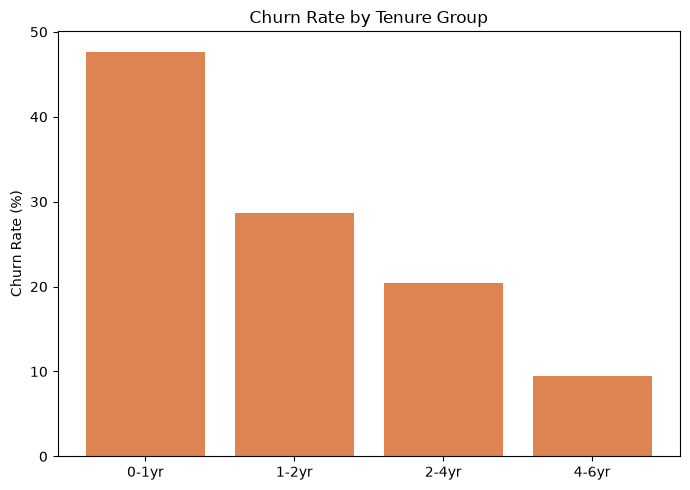

In [13]:
# 3. Churn rate by tenure group
tenure_churn = df.groupby('TenureGroup')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(7, 5))
plt.bar(tenure_churn.index.astype(str), tenure_churn.values, color='#DD8452')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Tenure Group')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'churn_by_tenure.png'), dpi=150)
plt.show()

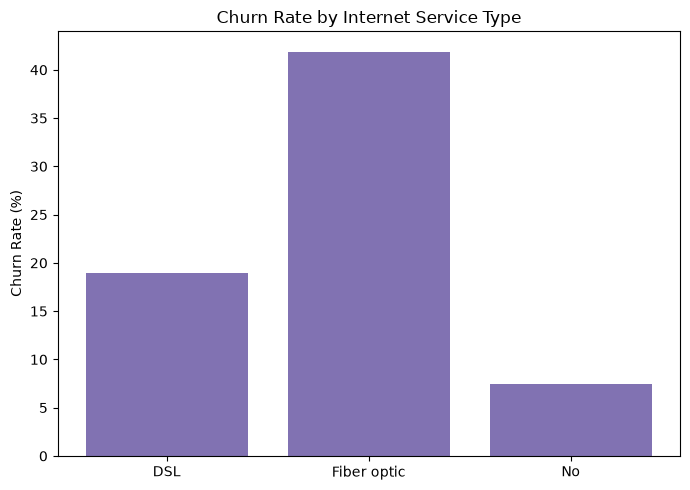

In [14]:
# 4. Churn rate by Internet Service type
internet_churn = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(7, 5))
plt.bar(internet_churn.index, internet_churn.values, color='#8172B2')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Internet Service Type')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'churn_by_internet.png'), dpi=150)
plt.show()

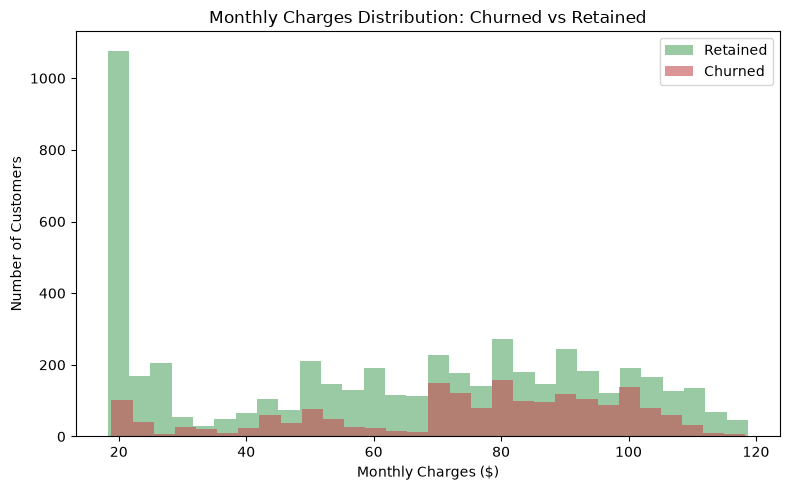

In [15]:
# 5. Monthly charges distribution: churned vs retained (histogram, overlaid)
plt.figure(figsize=(8, 5))
plt.hist(df[df['Churn'] == 'No']['MonthlyCharges'], bins=30, alpha=0.6, label='Retained', color='#55A868')
plt.hist(df[df['Churn'] == 'Yes']['MonthlyCharges'], bins=30, alpha=0.6, label='Churned', color='#C44E52')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Number of Customers')
plt.title('Monthly Charges Distribution: Churned vs Retained')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'churn_by_monthly_charges.png'), dpi=150)
plt.show()

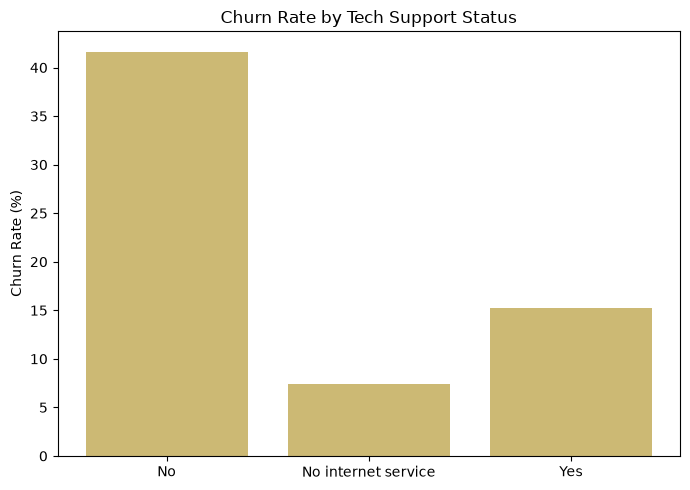

In [16]:
# 6. Churn by Tech Support (compounding factor example)
tech_churn = df.groupby('TechSupport')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(7, 5))
plt.bar(tech_churn.index, tech_churn.values, color='#CCB974')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Tech Support Status')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'churn_by_techsupport.png'), dpi=150)
plt.show()